
================ ERI ABLATION STUDY (MODEL-WISE) ================

            Model  Accuracy_Stability_Mean  LMOS_Stability_Mean  ERI (Full)  ERI w/o Accuracy  ERI w/o LMOS
       Custom CNN                 0.930235             0.658630    0.794433          0.329315      0.465118
      Densenet121                 0.984899             0.825087    0.904993          0.412544      0.492449
InceptionResnetV2                 0.976570             0.746269    0.861420          0.373134      0.488285
     Inception V3                 0.970310             0.696115    0.833213          0.348058      0.485155
     MobileNet V2                 0.970444             0.840393    0.905418          0.420196      0.485222
         ResNet50                 0.826317             0.828084    0.827201          0.414042      0.413158
            VGG16                 0.946948             0.703300    0.825124          0.351650      0.473474
         Xception                 0.988700             0.880500    0

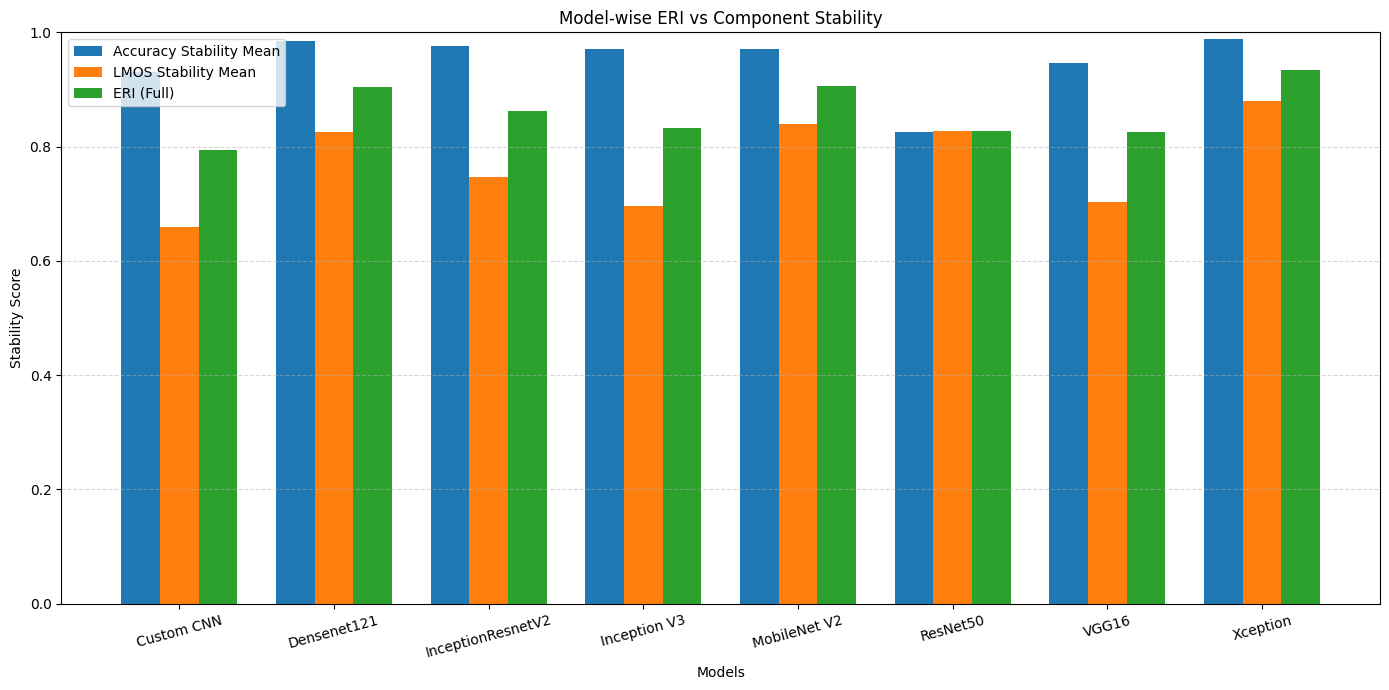

Saved: eri_modelwise_components.png


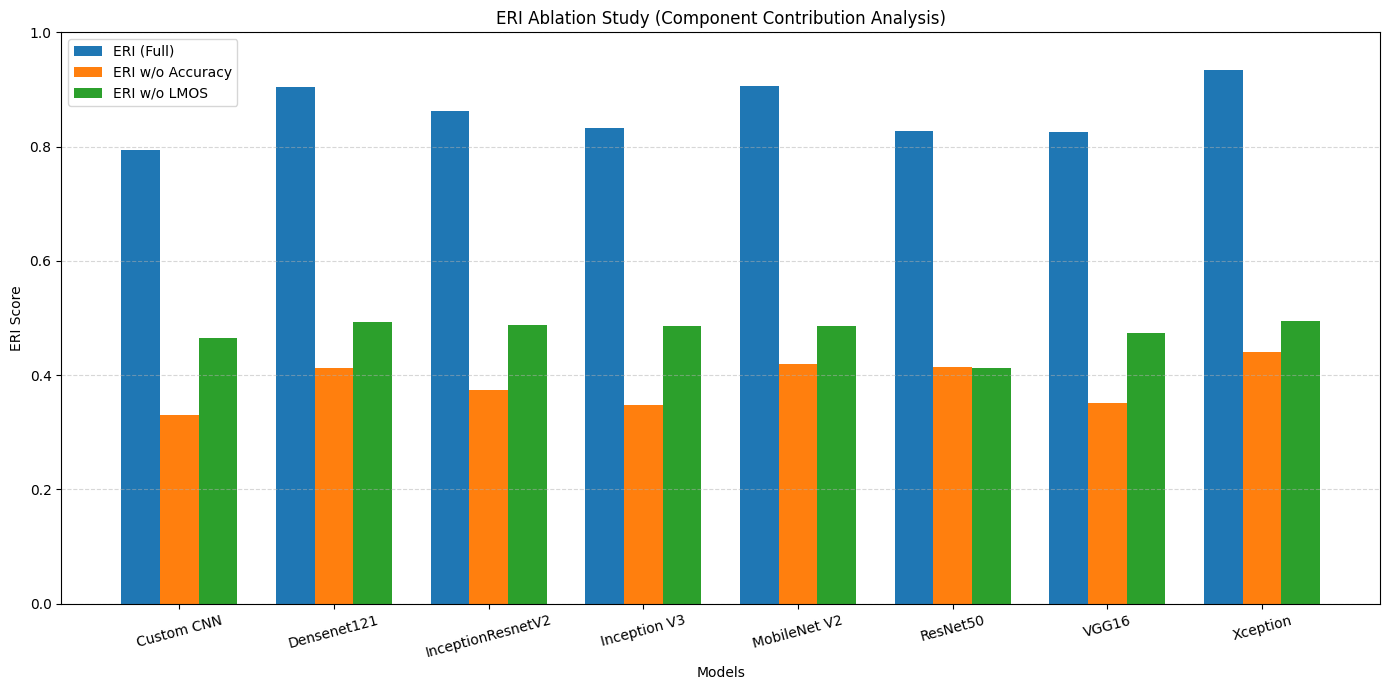

Saved: eri_modelwise_ablation.png
Saved: eri_modelwise_ablation.csv


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ====================================================
# MODEL NAMES
# ====================================================

models = [
    "Custom CNN",
    "Densenet121",
    "InceptionResnetV2",
    "Inception V3",
    "MobileNet V2",
    "ResNet50",
    "VGG16",
    "Xception"
    
]



np.random.seed(42)

accuracy_stability_mean = [0.930235, 0.984899, 0.976570, 0.970310, 0.970444, 0.826317, 0.946948, 0.9887]
lmos_stability_mean     = [0.658630, 0.825087, 0.746269, 0.696115, 0.840393, 0.828084, 0.703300, 0.8805]

# ====================================================
# ERI COMPUTATION
# ====================================================

eri_full = [(a + l) / 2 for a, l in zip(accuracy_stability_mean, lmos_stability_mean)]
eri_no_accuracy = [l / 2 for l in lmos_stability_mean]
eri_no_lmos     = [a / 2 for a in accuracy_stability_mean]

# ====================================================
# TABLE WITH ABLATION
# ====================================================

df = pd.DataFrame({
    "Model": models,
    "Accuracy_Stability_Mean": accuracy_stability_mean,
    "LMOS_Stability_Mean": lmos_stability_mean,
    "ERI (Full)": eri_full,
    "ERI w/o Accuracy": eri_no_accuracy,
    "ERI w/o LMOS": eri_no_lmos
})

# ====================================================
# PRINT TABLE
# ====================================================

print("\n================ ERI ABLATION STUDY (MODEL-WISE) ================\n")
print(df.to_string(index=False))

# ====================================================
# PLOT 1: COMPONENT COMPARISON
# ====================================================

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(14,7))

plt.bar(x - width, accuracy_stability_mean, width, label="Accuracy Stability Mean")
plt.bar(x, lmos_stability_mean, width, label="LMOS Stability Mean")
plt.bar(x + width, eri_full, width, label="ERI (Full)")

plt.xticks(x, models, rotation=15)
plt.ylabel("Stability Score")
plt.xlabel("Models")
plt.title("Model-wise ERI vs Component Stability")

plt.ylim(0.0, 1.0)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()

plt.savefig("eri_modelwise_components.png", dpi=600, bbox_inches='tight')
plt.show()

print("Saved: eri_modelwise_components.png")

# ====================================================
# PLOT 2: ABLATION VISUALIZATION
# ====================================================

plt.figure(figsize=(14,7))

plt.bar(x - width, eri_full, width, label="ERI (Full)")
plt.bar(x, eri_no_accuracy, width, label="ERI w/o Accuracy")
plt.bar(x + width, eri_no_lmos, width, label="ERI w/o LMOS")

plt.xticks(x, models, rotation=15)
plt.ylabel("ERI Score")
plt.xlabel("Models")
plt.title("ERI Ablation Study (Component Contribution Analysis)")

plt.ylim(0.0, 1.0)

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()

plt.savefig("eri_modelwise_ablation.png", dpi=600, bbox_inches='tight')
plt.show()

print("Saved: eri_modelwise_ablation.png")

# ====================================================
# SAVE TABLE
# ====================================================

df.to_csv("eri_modelwise_ablation.csv", index=False)

print("Saved: eri_modelwise_ablation.csv")